# Rever Apartment Price Segmentation | Classification
**Portfolio Case Study · PropTech · Vietnam · scikit-learn**

> **Business question:** Chỉ từ đặc điểm vật lý và vị trí, có thể dự đoán căn hộ thuộc phân khúc **Bình dân / Trung cấp / Cao cấp** để hỗ trợ gắn nhãn và sàng lọc tin đăng hay không?

**TL;DR (báo cáo từ notebook gốc, chưa tái kiểm chứng):** 189 tin đăng; ngưỡng phân khúc **≤ 4,4 tỷ**, **4,4–7 tỷ**, **> 7 tỷ VNĐ**. Trong báo cáo ban đầu, SVM-RBF đạt **84,80% CV Accuracy**, Random Forest đạt **84,11% CV Accuracy** và **73,68% Test Accuracy** (38 mẫu). **Các con số trên chỉ mang tính tham chiếu** vì file CSV gốc chưa được cung cấp cùng notebook; bảng và biểu đồ bên dưới sẽ được tính lại khi có dữ liệu.

**Scope:** Data QA → EDA → KNN & entropy tự cài đặt → cây quyết định/KNN → benchmark 10 mô hình → held-out evaluation → diễn giải và demo. **Không dùng `price_vnd` hay `price_per_m2` làm đặc trưng.**

## 1. Setup & data contract

- Đặt `rever_apartments_clean_fetcher.csv` vào thư mục `data/` (hoặc cạnh notebook). Notebook **không tự tạo dữ liệu giả**.
- `price_segment` dùng **ngưỡng cố định** từ snapshot gốc để tái lập định nghĩa nhãn. Các ngưỡng ban đầu được ước lượng trên chính snapshot này; cần kiểm định độc lập trước khi vận hành ngoài thực tế.
- Random seed = 42; 80/20 stratified holdout; CV 5-fold **chỉ trên tập train**.

In [6]:
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

SEED = 42
LABELS = ["Bình dân", "Trung cấp", "Cao cấp"]
BINS = [-np.inf, 4.4e9, 7.0e9, np.inf]
NUM = ["area_m2", "bedrooms", "bathrooms", "area_per_bedroom", "total_rooms", "has_balcony_info"]
CAT = ["district", "balcony_direction_clean"]
FEATURES = NUM + CAT
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
sns.set_theme(style="whitegrid", context="notebook")

In [7]:
filename = "rever_apartments_clean_fetcher.csv"
paths = [Path("data") / filename, Path(filename), Path("..") / "data" / filename]
data_path = next((p for p in paths if p.is_file()), None)
if data_path is None:
    raise FileNotFoundError(f"Thiếu {filename}. Hãy đặt file vào data/ hoặc cạnh notebook (xem README.md).")

df = pd.read_csv(data_path)
required = ["price_vnd", "area_m2", "bedrooms", "bathrooms", "district", "balcony_direction"]
missing = sorted(set(required) - set(df.columns))
if missing:
    raise ValueError(f"CSV thiếu các cột bắt buộc: {missing}")
for col in ["price_vnd", "area_m2", "bedrooms", "bathrooms"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
quality = pd.DataFrame({"dtype": df.dtypes.astype(str), "missing_%": df.isna().mean().mul(100).round(1)})
print(f"Source: {data_path} | Rows: {len(df)} | Columns: {df.shape[1]} | Duplicate rows: {df.duplicated().sum()}")
display(quality.sort_values("missing_%", ascending=False).head(12))

df = df.dropna(subset=["price_vnd", "area_m2", "bedrooms", "bathrooms", "district"])
df = df.loc[(df.price_vnd > 0) & (df.area_m2 > 0)].copy()
if len(df) < 30:
    raise ValueError("Dữ liệu hợp lệ quá ít (<30 dòng) để huấn luyện và kiểm định.")
df["price_segment"] = pd.cut(df.price_vnd, bins=BINS, labels=LABELS)
print("Valid rows:", len(df), "| Classes:", df.price_segment.value_counts().to_dict())

Source: ..\data\rever_apartments_clean_fetcher.csv | Rows: 189 | Columns: 20 | Duplicate rows: 0


,dtype,missing_%
view_type,float64,100.0
floor,float64,100.0
discount_pct,float64,100.0
old_price_vnd,float64,100.0
furnished,float64,100.0
listing_date,float64,100.0
balcony_direction,str,31.7
street,str,0.5
project_name,str,0.0
listing_url,str,0.0


Valid rows: 189 | Classes: {'Bình dân': 71, 'Cao cấp': 63, 'Trung cấp': 55}


## 2. Feature engineering & exploratory analysis

Tính các biến tổng hợp **theo từng dòng**, không học thống kê từ tập test. Không dùng giá rao và đơn giá/m² làm đầu vào (target leakage). Các cột ID, URL, văn bản tự do và cột rỗng hoàn toàn không đưa vào mô hình. `area_per_bedroom` chỉ là đặc trưng mô tả, không phải tỷ lệ tài chính.

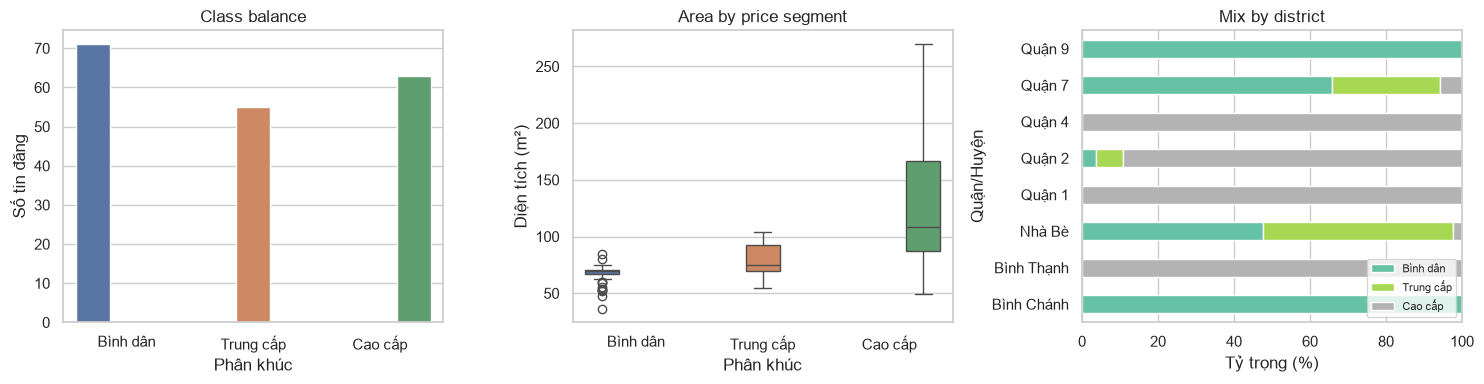

In [8]:
def make_features(data):
    x = data.copy()
    x["has_balcony_info"] = x.balcony_direction.notna().astype(int)
    x["balcony_direction_clean"] = x.balcony_direction.fillna("Chưa rõ")
    x["area_per_bedroom"] = x.area_m2 / x.bedrooms.replace(0, 1)
    x["total_rooms"] = x.bedrooms + x.bathrooms
    return x[FEATURES]

X, y = make_features(df), df["price_segment"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x="price_segment", order=LABELS, hue="price_segment",
              palette="deep", legend=False, ax=axes[0])
axes[0].set(title="Class balance", xlabel="Phân khúc", ylabel="Số tin đăng")
sns.boxplot(data=df, x="price_segment", y="area_m2", order=LABELS,
            hue="price_segment", palette="deep", legend=False, ax=axes[1])
axes[1].set(title="Area by price segment", xlabel="Phân khúc", ylabel="Diện tích (m²)")
pd.crosstab(df.district, y, normalize="index").reindex(columns=LABELS).mul(100).plot(
    kind="barh", stacked=True, ax=axes[2], colormap="Set2", legend=False)
axes[2].set(title="Mix by district", xlabel="Tỷ trọng (%)", ylabel="Quận/Huyện")
axes[2].legend(LABELS, fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

**EDA checkpoint:** Tập dữ liệu nhỏ và có nhiều tin cùng khu vực; tỷ trọng phân khúc theo quận chỉ mang tính mô tả, không chứng minh quan hệ nhân quả. Ngoại lệ diện tích có thể là căn hộ lớn thật, không tự động loại bỏ.

## 3. Algorithms from scratch — educational core

**KNN pseudocode:** (1) tính khoảng cách tới mọi mẫu train; (2) chọn `k` khoảng cách nhỏ nhất; (3) bỏ phiếu nhãn phổ biến nhất. **Cây quyết định:** chọn ngưỡng làm giảm Entropy/Gini tốt nhất; lặp đệ quy trên các nhánh, dừng ở điều kiện cắt tỉa. Cài đặt từ đầu chỉ nhằm minh họa, không dùng làm ứng viên production.

In [9]:
class KNNFromScratch:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X, self.y = np.asarray(X, dtype=float), np.asarray(y)
        return self

    def predict(self, X):
        result = []
        for row in np.asarray(X, dtype=float):
            neighbors = self.y[np.argsort(np.linalg.norm(self.X - row, axis=1))[:self.k]]
            result.append(Counter(neighbors).most_common(1)[0][0])
        return np.asarray(result)

def entropy(y):
    counts = np.unique(y, return_counts=True)[1]
    p = counts / counts.sum()
    return -np.sum(p * np.log2(p))

def gini(y):
    p = np.unique(y, return_counts=True)[1] / len(y)
    return 1 - np.square(p).sum()

def information_gain(feature, y, threshold):
    left, y = np.asarray(feature) <= threshold, np.asarray(y)
    if not left.any() or left.all():
        return 0.0
    return entropy(y) - left.mean() * entropy(y[left]) - (~left).mean() * entropy(y[~left])

## 4. Train/test split & leakage-safe pipeline

Mọi phép **fit** (imputation, scaling, one-hot encoding, model training) diễn ra **bên trong pipeline và từng fold**. Test để dành đánh giá cuối. Với dữ liệu lặp dự án, cần thêm group-based evaluation trước khi triển khai thực tế.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT),
])

def pipeline(model):
    return Pipeline([("prep", clone(preprocess)), ("model", clone(model))])

demo_train, demo_val = train_test_split(
    np.arange(len(X_train)), test_size=0.25, stratify=y_train, random_state=SEED)
demo_num = X_train[["area_m2", "bedrooms", "bathrooms"]].to_numpy()
scaler = StandardScaler().fit(demo_num[demo_train])
knn_scratch = KNNFromScratch(k=5).fit(scaler.transform(demo_num[demo_train]), y_train.iloc[demo_train])
scratch_pred = knn_scratch.predict(scaler.transform(demo_num[demo_val]))
print(f"Train/Test: {len(X_train)}/{len(X_test)} | Scratch KNN (train-only validation): "
      f"{accuracy_score(y_train.iloc[demo_val], scratch_pred):.2%}")
print(f"Train entropy: {entropy(y_train):.4f} bits | Gini: {gini(y_train):.4f}")
print("Information gain (area_m2):", {
    t: round(information_gain(X_train.area_m2, y_train, t), 4) for t in [65, 75, 85, 95]})

Train/Test: 151/38 | Scratch KNN (train-only validation): 57.89%
Train entropy: 1.5769 bits | Gini: 0.6630
Information gain (area_m2): {65: np.float64(0.0309), 75: np.float64(0.4051), 85: np.float64(0.3699), 95: np.float64(0.3343)}


## 5. Decision Tree & KNN — bias/variance

So sánh 3 cách xây cây bằng **CV train**. Cây giải thích ngắn được huấn luyện riêng trên diện tích/số phòng/quận để **ngưỡng diện tích vẫn mang đơn vị m²**; không đánh đồng đây là mô hình CV winner.

Gini · unpruned      | train 98.0% | CV 80.2%
Entropy · unpruned   | train 98.0% | CV 78.2%
Entropy · pruned     | train 82.1% | CV 74.2%
|--- area_m2 <= 80.58
|   |--- district_Quận 2 <= 0.50
|   |   |--- area_m2 <= 70.53
|   |   |   |--- class: Bình dân
|   |   |--- area_m2 >  70.53
|   |   |   |--- class: Bình dân
|   |--- district_Quận 2 >  0.50
|   |   |--- bathrooms <= 1.50
|   |   |   |--- class: Trung cấp
|   |   |--- bathrooms >  1.50
|   |   |   |--- class: Cao cấp
|--- area_m2 >  80.58
|   |--- district_Quận 2 <= 0.50
|   |   |--- area_m2 <= 104.51
|   |   |   |--- class: Trung cấp
|   |   |--- area_m2 >  104.51
|   |   |   |--- class: Cao cấp
|   |--- district_Quận 2 >  0.50
|   |   |--- class: Cao cấp



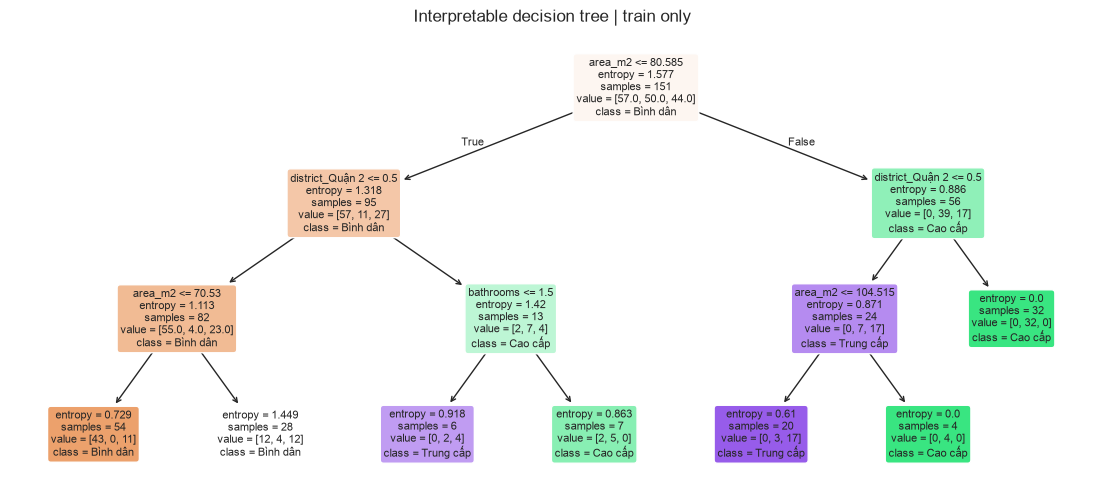

In [11]:
tree_variants = {
    "Gini · unpruned": DecisionTreeClassifier(random_state=SEED),
    "Entropy · unpruned": DecisionTreeClassifier(criterion="entropy", random_state=SEED),
    "Entropy · pruned": DecisionTreeClassifier(
        criterion="entropy", max_depth=4, min_samples_leaf=3, random_state=SEED),
}
for name, model in tree_variants.items():
    scores = cross_validate(pipeline(model), X_train, y_train, cv=CV, scoring="accuracy")
    fitted = pipeline(model).fit(X_train, y_train)
    print(f"{name:20} | train {fitted.score(X_train, y_train):.1%} | CV {scores['test_score'].mean():.1%}")

tree_X = pd.get_dummies(X_train[["area_m2", "bedrooms", "bathrooms", "district"]])
readable_tree = DecisionTreeClassifier(criterion="entropy", max_depth=3,
                                       min_samples_leaf=4, random_state=SEED).fit(tree_X, y_train)
print(export_text(readable_tree, feature_names=list(tree_X.columns)))
plt.figure(figsize=(14, 6))
plot_tree(readable_tree, feature_names=list(tree_X.columns),
          class_names=list(readable_tree.classes_), filled=True, rounded=True, fontsize=8)
plt.title("Interpretable decision tree | train only")
plt.show()

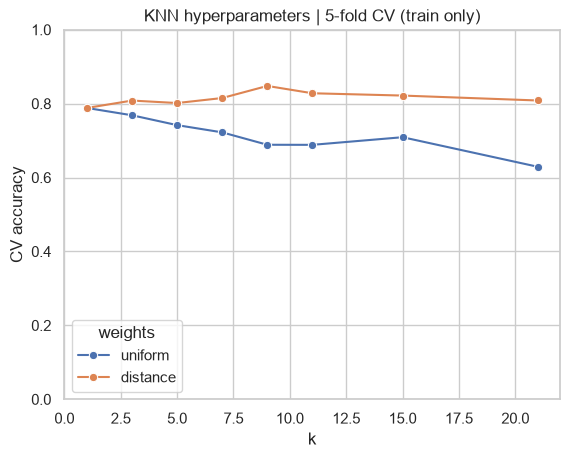

,k,weights,CV accuracy
12,9,distance,0.848
13,11,distance,0.828
14,15,distance,0.822
11,7,distance,0.815
15,21,distance,0.808


d:\File Downloads\Data-Mining-with-Python-main\.notebook-venv\Lib\site-packages\sklearn\inspection\_plot\decision_boundary.py:392: UserWarning: 'cmap' is ignored in favor of 'multiclass_colors' in the multiclass case.
  warnings.warn(


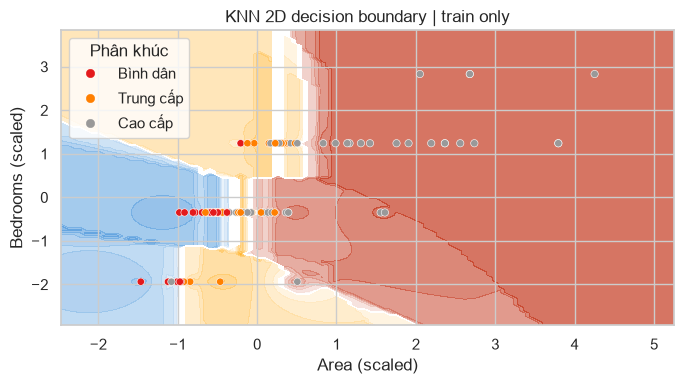

In [12]:
knn_rows = []
for weight in ["uniform", "distance"]:
    for k in [1, 3, 5, 7, 9, 11, 15, 21]:
        scores = cross_validate(pipeline(KNeighborsClassifier(n_neighbors=k, weights=weight)),
                                X_train, y_train, cv=CV, scoring="accuracy")
        knn_rows.append({"k": k, "weights": weight, "CV accuracy": scores["test_score"].mean()})
knn_search = pd.DataFrame(knn_rows)
sns.lineplot(data=knn_search, x="k", y="CV accuracy", hue="weights", marker="o")
plt.title("KNN hyperparameters | 5-fold CV (train only)")
plt.ylim(0, 1)
plt.show()
display(knn_search.sort_values("CV accuracy", ascending=False).head(5).round(3))

# 2D decision boundary: illustration only (not the complete-feature KNN model).
area_beds = StandardScaler().fit_transform(X_train[["area_m2", "bedrooms"]])
encoded_labels = pd.Categorical(y_train, categories=LABELS).codes
knn_2d = KNeighborsClassifier(n_neighbors=7, weights="distance").fit(area_beds, encoded_labels)
fig, ax = plt.subplots(figsize=(7, 4))
DecisionBoundaryDisplay.from_estimator(knn_2d, area_beds, cmap="Pastel1", alpha=0.65, ax=ax)
points = ax.scatter(area_beds[:, 0], area_beds[:, 1], c=encoded_labels,
                    cmap="Set1", edgecolors="white", linewidth=0.4, s=28)
ax.legend(points.legend_elements()[0], LABELS, title="Phân khúc", loc="best")
ax.set(title="KNN 2D decision boundary | train only", xlabel="Area (scaled)", ylabel="Bedrooms (scaled)")
plt.tight_layout()
plt.show()

## 6. Model benchmark — 6 algorithm families + 2 baselines

Đánh giá **10 cấu hình** thuộc các nhóm Decision Tree, KNN, Naive Bayes, SVM, SGD và tree ensembles (Random Forest, Extra Trees), cộng Dummy/Logistic Regression. **Chọn mô hình theo 5-fold CV Macro-F1**, không theo Test Accuracy. KNN sweep phía trên là phân tích độ nhạy; các cấu hình benchmark được cố định để tránh tinh chỉnh lặp trên cùng test.

In [13]:
models = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree": tree_variants["Entropy · pruned"],
    "KNN": KNeighborsClassifier(n_neighbors=5, weights="distance"),
    "Gaussian Naive Bayes": GaussianNB(),
    "SVM Linear": SVC(kernel="linear", random_state=SEED),
    "SVM RBF": SVC(kernel="rbf", C=2, random_state=SEED),
    "SGD": SGDClassifier(loss="hinge", penalty="l2", max_iter=1000, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SEED),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, max_depth=6, random_state=SEED),
}
records = []
for name, model in models.items():
    scores = cross_validate(pipeline(model), X_train, y_train, cv=CV,
                            scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"})
    records.append({"Model": name, "CV Accuracy": scores["test_accuracy"].mean(),
                    "CV Macro-F1": scores["test_macro_f1"].mean(),
                    "CV Acc SD": scores["test_accuracy"].std()})
results = pd.DataFrame(records).sort_values("CV Macro-F1", ascending=False).reset_index(drop=True)
best_name = results.loc[0, "Model"]
display(results.to_string(formatters={column: "{:.1%}".format
                                     for column in ["CV Accuracy", "CV Macro-F1", "CV Acc SD"]},
                              index=False))
print("CV-selected model:", best_name)

'               Model CV Accuracy CV Macro-F1 CV Acc SD\n             SVM RBF       84.8%       83.9%      7.1%\n       Random Forest       84.1%       83.0%      4.4%\n         Extra Trees       83.5%       82.1%      6.2%\n                 KNN       80.2%       79.8%      4.6%\n          SVM Linear       80.8%       79.6%      4.6%\n Logistic Regression       80.2%       78.6%      5.4%\n                 SGD       78.8%       77.2%      4.3%\n       Decision Tree       74.2%       72.5%      5.2%\nGaussian Naive Bayes       51.7%       47.3%      7.0%\n               Dummy       37.7%       18.3%      1.4%'

CV-selected model: SVM RBF


## 7. Held-out test, uncertainty & explainability

**Chỉ sau khi khóa lựa chọn CV**, mới mở tập test. Bootstrap 95% CI bên dưới lấy lại mẫu các **dự đoán đúng/sai trên 1 holdout**; không phản ánh đầy đủ bất định theo thời gian, khu vực hay một bộ dữ liệu mới. Confusion matrices các mô hình khác chỉ để chẩn đoán, **không đổi lựa chọn mô hình dựa trên kết quả test**.

Chosen: SVM RBF | Test Accuracy: 71.1% | Macro-F1: 70.0%
Bootstrap 95% CI for test accuracy: [57.9%, 84.2%] (n=38)
              precision    recall  f1-score   support

    Bình dân       0.62      0.57      0.59        14
   Trung cấp       0.55      0.55      0.55        11
     Cao cấp       0.93      1.00      0.96        13

    accuracy                           0.71        38
   macro avg       0.70      0.71      0.70        38
weighted avg       0.70      0.71      0.71        38



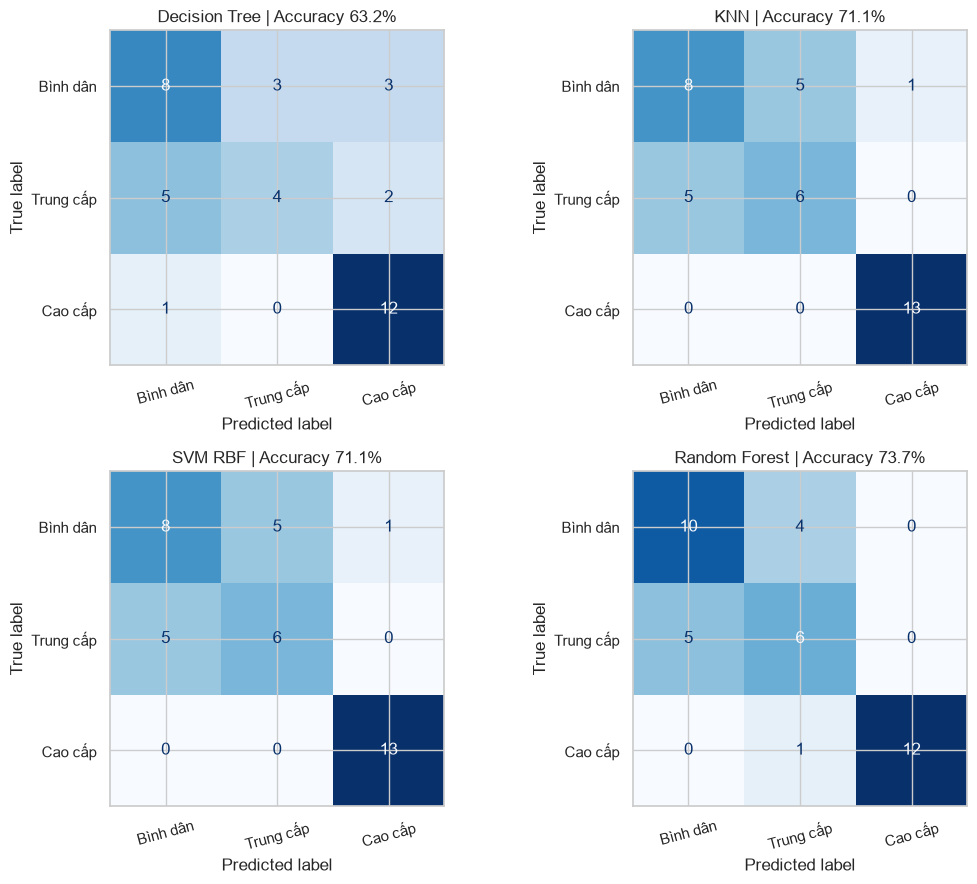

In [14]:
fitted = {name: pipeline(models[name]).fit(X_train, y_train)
          for name in set([best_name, "Decision Tree", "KNN", "SVM RBF", "Random Forest"])}
best_model = fitted[best_name]
y_pred = best_model.predict(X_test)
correct = (np.asarray(y_test) == y_pred).astype(float)
rng = np.random.default_rng(SEED)
ci = np.percentile(rng.choice(correct, size=(2000, len(correct)), replace=True).mean(axis=1), [2.5, 97.5])
print(f"Chosen: {best_name} | Test Accuracy: {correct.mean():.1%} | Macro-F1: {f1_score(y_test, y_pred, average='macro'):.1%}")
print(f"Bootstrap 95% CI for test accuracy: [{ci[0]:.1%}, {ci[1]:.1%}] (n={len(y_test)})")
print(classification_report(y_test, y_pred, labels=LABELS, zero_division=0))

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, name in zip(axes.flat, ["Decision Tree", "KNN", "SVM RBF", "Random Forest"]):
    p = fitted[name].predict(X_test)
    ConfusionMatrixDisplay.from_predictions(y_test, p, labels=LABELS,
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{name} | Accuracy {accuracy_score(y_test, p):.1%}")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

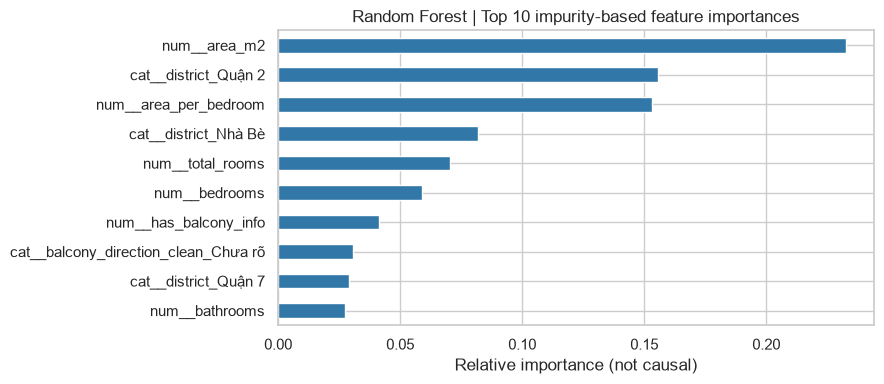

,n,accuracy
district,,
Nhà Bè,19,0.526
Quận 2,11,1.000
Quận 7,6,1.000
Bình Chánh,1,0.000
Bình Thạnh,1,1.000


Cảnh báo: slice có n nhỏ (đặc biệt n=1) không đủ cơ sở kết luận 100% hiệu năng.


In [15]:
rf = fitted["Random Forest"]
importance = pd.Series(rf.named_steps["model"].feature_importances_,
                       index=rf.named_steps["prep"].get_feature_names_out()).nlargest(10)
importance.sort_values().plot.barh(figsize=(9, 4), color="#3177a8")
plt.title("Random Forest | Top 10 impurity-based feature importances")
plt.xlabel("Relative importance (not causal)")
plt.tight_layout()
plt.show()

slice_eval = pd.DataFrame({"district": X_test.district,
                           "correct": np.asarray(y_test) == rf.predict(X_test)})
slices = slice_eval.groupby("district").correct.agg(n="size", accuracy="mean")
display(slices.sort_values("n", ascending=False).round(3))
print("Cảnh báo: slice có n nhỏ (đặc biệt n=1) không đủ cơ sở kết luận 100% hiệu năng.")

## 8. Inference demo — 3 căn hộ minh họa

Đầu vào chỉ cần các trường gốc; đặc trưng được tạo lại bằng cùng `make_features`. Dùng Random Forest (mô hình diễn giải trong case study gốc) cho bảng xác suất. **`predict_proba` chưa hiệu chuẩn (calibration)**; chỉ dùng minh họa, không nên tự động ra quyết định thương mại.

In [16]:
new_listings = pd.DataFrame([
    {"description": "Dragon Hill / Nhà Bè", "area_m2": 68, "bedrooms": 2, "bathrooms": 2,
     "district": "Nhà Bè", "balcony_direction": "Đông Nam"},
    {"description": "Sky Garden / Quận 7", "area_m2": 95, "bedrooms": 3, "bathrooms": 2,
     "district": "Quận 7", "balcony_direction": "Nam"},
    {"description": "Thảo Điền / Quận 2", "area_m2": 115, "bedrooms": 3, "bathrooms": 2,
     "district": "Quận 2", "balcony_direction": "Đông Nam"},
])
new_X = make_features(new_listings)
demo = new_listings[["description", "district", "area_m2", "bedrooms"]].copy()
demo["Predicted segment"] = rf.predict(new_X)
prob = pd.DataFrame(rf.predict_proba(new_X), columns=rf.classes_)
for label in LABELS:
    demo[f"P({label})"] = prob[label].round(3)
display(demo)

,description,district,area_m2,bedrooms,Predicted segment,P(Bình dân),P(Trung cấp),P(Cao cấp)
0,Dragon Hill / Nhà Bè,Nhà Bè,68,2,Bình dân,0.744,0.248,0.008
1,Sky Garden / Quận 7,Quận 7,95,3,Trung cấp,0.063,0.687,0.250
2,Thảo Điền / Quận 2,Quận 2,115,3,Cao cấp,0.018,0.019,0.963


## 9. Business takeaways & limitations

**Ứng dụng tiềm năng:** (1) gắn nhãn và phân luồng tin đăng; (2) ưu tiên kiểm tra những tin có phân khúc dự báo khác giá chào; (3) giải thích bằng luật của cây quyết định; (4) hỗ trợ tư vấn nhờ căn hộ tương đồng (KNN). Bài toán **lead scoring** cần dữ liệu hành vi khách hàng riêng, không suy ra từ dataset căn hộ này.

**Insight để điều tra:** địa bàn (đặc biệt Nhà Bè, Quận 2, Quận 7) và diện tích có thể giải thích một phần phân khúc giá; mức độ lỗi theo quận phụ thuộc số quan sát. Những ví dụ dự án được nêu trong notebook gốc chỉ là giả thuyết khảo sát, **chưa xác minh bằng phân tích từng dự án**.

**Rủi ro trước production:** snapshot chỉ có khoảng 189 tin; các tin đăng có thể trùng dự án; thiếu tuổi dự án, chất lượng nội thất, pháp lý và thời điểm đăng; nhãn được định nghĩa từ **giá chào**, không phải giá giao dịch. Cần kiểm thử **theo thời gian/dự án**, dữ liệu nhiều hơn, hiệu chuẩn xác suất, chi phí lỗi theo lớp và drift monitoring. Không khẳng định độ trễ dự đoán hay chất lượng production khi chưa đo.

**Takeaway:** Chọn mô hình theo **CV Macro-F1**, kiểm định trên holdout chỉ một lần, và báo cáo trung thực khoảng bất định. Đây là một **proof of concept học thuật**, không phải hệ thống định giá được thẩm định.